# 1. Electricity price data from a public API

The scheduling model needs the **Nord Pool system price**: the unconstrained Nordic day-ahead price that the
forward contracts settle against. Three things are taken from the spot history in this notebook:

1. the **seasonal profile** of the price, written as a cosine $s(w) = A\cos(2\pi (w - w_0)/52)$ over the week of the year $w$;
2. the **starting level** $\xi_0$ of the long-term price factor at the beginning of the planning horizon;
3. a weekly price series that notebook 2 uses to measure how price and inflow move together.

The dynamics of the two price factors (mean reversion and volatilities) are *not* estimated here but from the forward
curve in notebook 3: the spot history mixes both factors and cannot separate them, while the forward curve shows
their term structure directly.

### Where the data comes from
Nord Pool's own market-data API requires a paid subscription. The same system price is republished, hour by hour and
free of charge, by the Danish TSO Energinet on **Energi Data Service** (dataset `Elspotprices`, price area `SYSTEM`,
no API key). That is what `gdsddp.data.fetch_system_price` downloads, one calendar year per request. Energinet
stopped publishing the SYSTEM area in February 2025, so for later dates use Nord Pool's data portal or the ENTSO-E
transparency platform (free token). For a single bidding zone such as NO4 the public sources are ENTSO-E and, from
December 2021, `hvakosterstrommen.no`; the thesis used NTE's own NO4 export.

Set `USE_SAMPLE = True` to run offline on the synthetic sample shipped in `data/sample/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gdsddp import plots
from gdsddp.data import RAW, SAMPLE, PROCESSED, save_json, load_json
plots.style()
PROCESSED.mkdir(parents=True, exist_ok=True)

In [2]:
USE_SAMPLE = False          # True: skip the API and use data/sample/system_price_daily.csv
START, END = "2015-01-01", "2024-12-31"
SEASON_WINDOW = ("2015-01-01", "2020-12-31")   # calm years for the seasonal fit (2021-22 is a different regime)

from gdsddp.data import fetch_system_price, load_price_file, weekly_mean, fit_season
cache = RAW / "system_price_hourly.csv"         # raw/ is git-ignored
source = "sample"
if not USE_SAMPLE:
    try:
        source = "data/raw/system_price_hourly.csv (earlier API download)" if cache.exists() else "Energi Data Service API (now cached in data/raw/)"
        price = fetch_system_price(START, END, cache=cache)
    except Exception as exc:                    # offline or API change: fall back to the sample
        print("API fetch failed:", exc)
        USE_SAMPLE = True
if USE_SAMPLE:
    price = load_price_file(SAMPLE / "system_price_daily.csv")
print(f"source: {source}; {len(price)} records from {price.index.min().date()} to {price.index.max().date()}")
price.tail()

source: data/raw/system_price_hourly.csv (earlier API download); 87648 records from 2014-12-31 to 2024-12-30


date
2024-12-30 18:00:00    16.84
2024-12-30 19:00:00    13.02
2024-12-30 20:00:00     9.55
2024-12-30 21:00:00     8.01
2024-12-30 22:00:00     6.77
Name: price_eur_mwh, dtype: float64

## Weekly means

The model works in weekly steps, so the hourly (or daily) series is averaged per calendar week (Monday to Sunday).
The week of the year `woy` is the ISO week number clipped to 52, which is the seasonal index used everywhere in the code.

       count       mean        std     min        25%       50%     75%  \
price  521.0  46.203146  44.109221  1.6575  24.390357  33.87994  51.775   
woy    521.0  26.646833  15.049215  1.0000  14.000000  27.00000  40.000   

              max  
price  319.149763  
woy     52.000000  


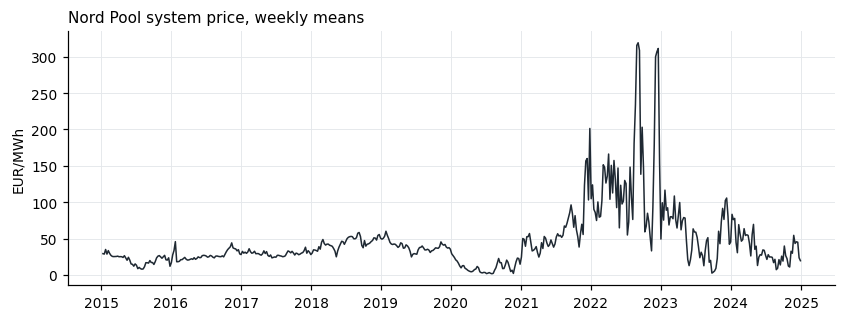

In [3]:
weekly = weekly_mean(price)
weekly.to_csv(PROCESSED / "price_weekly.csv")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(weekly.index, weekly["price"], color=plots.INK, lw=1)
ax.set_ylabel("EUR/MWh"); ax.set_title("Nord Pool system price, weekly means")
print(weekly.describe().T)

## Seasonal profile

The price has a clear yearly cycle (cold, dark winters). We fit $P_t = c + A\cos(2\pi(w_t - w_0)/52)$ by least squares on
the calm window; the amplitude $A$ and the phase $w_0$ (the week where the cycle peaks) are the two seasonal parameters of
the price model. The figure shows the average price per week of the year with its 10–90 % band and the fitted cosine.

amplitude A = 4.00 EUR/MWh, phase w0 = 50.8 weeks, level c = 28.5


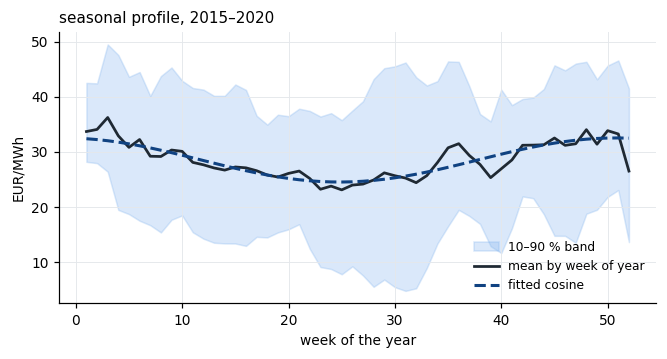

In [4]:
season = fit_season(weekly, *SEASON_WINDOW)
print(f"amplitude A = {season['season_amplitude']:.2f} EUR/MWh, phase w0 = {season['season_phase']:.1f} weeks, level c = {season['level']:.1f}")
win = weekly[(weekly.index >= SEASON_WINDOW[0]) & (weekly.index <= SEASON_WINDOW[1])]
clim = win.groupby("woy")["price"].agg(["mean", lambda s: s.quantile(0.1), lambda s: s.quantile(0.9)])
clim.columns = ["mean", "p10", "p90"]
w = np.arange(1, 53)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.fill_between(w, clim["p10"], clim["p90"], color=plots.RAMP[0], alpha=0.3, label="10–90 % band")
ax.plot(w, clim["mean"], color=plots.INK, lw=1.8, label="mean by week of year")
ax.plot(w, season["level"] + season["season_amplitude"] * np.cos(2 * np.pi * (w - season["season_phase"]) / 52), color=plots.RAMP[3], lw=2, ls="--", label="fitted cosine")
ax.set_xlabel("week of the year"); ax.set_ylabel("EUR/MWh"); ax.set_title(f"seasonal profile, {SEASON_WINDOW[0][:4]}–{SEASON_WINDOW[1][:4]}"); ax.legend();

## Starting level and a sanity check on the dynamics

The long-term factor starts the horizon at $\xi_0$. We take the mean deseasonalised price over the last 52 weeks of the
data (the planner's current view of the level). The last cell fits a plain AR(1) to the deseasonalised weekly price: its
coefficient lies between the mean reversion of the short-term factor (about 0.98 per week in the literature) and 1
(the random-walk long-term factor), which is what a mixture of the two factors should show. The proper separation is done
on the forward curve in notebook 3.

In [5]:
deseason = weekly["price"] - season["season_amplitude"] * np.cos(2 * np.pi * (weekly["woy"] - season["season_phase"]) / 52)
xi0 = float(deseason.iloc[-52:].mean())
x, y = deseason.to_numpy()[:-1], deseason.to_numpy()[1:]
phi_ar1 = np.cov(x, y, bias=True)[0, 1] / x.var()
print(f"xi_0 (mean deseasonalised price over the last 52 weeks) = {xi0:.1f} EUR/MWh")
print(f"AR(1) coefficient of the deseasonalised weekly price: {phi_ar1:.3f}")
params = {"season_amplitude": season["season_amplitude"], "season_phase": season["season_phase"], "xi0": xi0,
          "season_window": list(SEASON_WINDOW), "source": source, "last_week": str(weekly.index[-1].date())}
save_json(params, PROCESSED / "price_season.json")
print(json.dumps(params, indent=2))

xi_0 (mean deseasonalised price over the last 52 weeks) = 36.2 EUR/MWh
AR(1) coefficient of the deseasonalised weekly price: 0.877
{
  "season_amplitude": 3.996188379223248,
  "season_phase": 50.7928101651273,
  "xi0": 36.174546710050365,
  "season_window": [
    "2015-01-01",
    "2020-12-31"
  ],
  "source": "data/raw/system_price_hourly.csv (earlier API download)",
  "last_week": "2024-12-29"
}
